# Absorbing boundaries

The FFT makes the grid periodic: a wave that leaves on the right comes back on the left. To simulate
an open system, e.g. scattering or ionization, the wave has to be removed near the edges. The usual way is
a *complex absorbing potential* (CAP) $-iW(x)$ with $W \ge 0$ in a layer at each edge, which damps $\psi$
by $e^{-W\,\Delta t}$ in each step. A CAP is never perfect:

* if it rises too steeply, it *reflects* the wave like any other potential step, above all slow waves
  with long wavelengths;
* if it is too weak, fast waves cross the layer before they are absorbed, are *transmitted* and come
  back from the other side of the grid.

A wider layer helps with both but costs grid points. This notebook measures the reflection and transmission
probabilities $R(E)$ and $T(E)$ of the absorbers in `so_schroedinger`:

* `ExpAbsorber1d`: an imaginary part that rises exponentially towards the edge;
* `PowerAbsorber1d`: $-i\eta\,u^n$, with $u$ rising from 0 to 1 across the layer ($n = 2$ by default, like
  `BoundaryAbsorber2d` in 2d);
* `ManolopoulosAbsorber1d`: the *transmission-free* CAP of Manolopoulos, J. Chem. Phys. **117**, 9552 (2002).
  It diverges at the edge, so nothing gets through, and its shape is chosen to keep $R < 1\%$ for all
  energies above a chosen $E_\mathrm{min}$. That energy fixes the width of the layer.
* `MaskAbsorber1d`: multiplies $\psi$ by $\cos^{1/8}(\pi u/2)$ in each step, a mask popular in strong-field
  physics (Krause, Schafer and Kulander, Phys. Rev. A **45**, 4998 (1992)).

In [1]:
# On Colab or JupyterLite (or anywhere without the package), install it first:
try:
    import so_schroedinger  # noqa: F401
except ImportError:
    import sys

    if sys.platform == "emscripten":  # JupyterLite: the package comes with the site
        %pip install so_schroedinger
    else:
        %pip install -q git+https://github.com/aeberspaecher/splitoperator

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72

## The absorbers

We give all of them the width of the Manolopoulos absorber for $E_\mathrm{min} = 0.5$ (wave number
$k_\mathrm{min} = 1$, wavelength $2\pi$), $w = c/(2\delta k_\mathrm{min}) \approx 6.6$, about one wavelength.
The strengths of the other absorbers are typical choices, not tuned.

w = 6.56


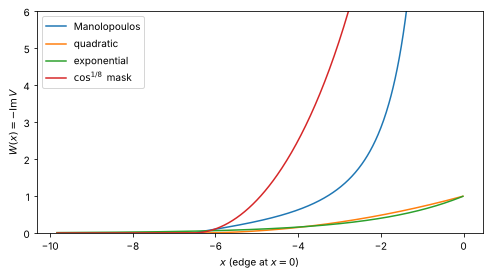

In [3]:
L, dt = 600.0, 0.01
E_min = 0.5
w = so.ManolopoulosAbsorber1d(E_min, 0.0, 1.0).width
absorbers = {  # functions of the grid boundaries (x0, x1)
    "Manolopoulos": lambda s: so.ManolopoulosAbsorber1d(E_min, *s),
    "quadratic": lambda s: so.PowerAbsorber1d(w, 1.0, *s),
    "exponential": lambda s: so.ExpAbsorber1d(0.0, -1.0, 1.0, w / 3, *s),
    r"$\cos^{1/8}$ mask": lambda s: so.MaskAbsorber1d(w, dt, *s),
}

x = np.linspace(-1.5 * w, 0.0, 600, endpoint=False)
fig, ax = plt.subplots()
for name, make in absorbers.items():
    ax.plot(x, -np.imag(make((-L, 0.0)).V(x, 0.0)), label=name)
ax.set(xlabel=r"$x$ (edge at $x = 0$)", ylabel="$W(x) = -\\mathrm{Im}\\,V$", ylim=(0, 6))
ax.legend()
print(f"w = {w:.2f}")

The Manolopoulos absorber starts slowly, grows like $1/(x_\mathrm{edge} - x)^2$ and diverges at the edge,
where its last grid point sets $\psi = 0$. The mask, written as a potential, is
$W = -\ln(\cos^{1/8}(\pi u/2))/\Delta t$, which also diverges at the edge (in floating point it ends at
$\cos^{1/8}(\pi/2) \approx 0.009$).

## Measuring reflection and transmission

A wavepacket runs into the absorber at the right edge, and we wait until all of it has been absorbed,
has come back, or has crossed the edge. The reflected wave moves to the left, so its momentum distribution
at $-k$, divided by the initial one at $+k$, is the reflection probability. What moves to the right in the
left half of the grid has passed both layers: the one at the right edge and, after crossing the periodic
boundary, the one at the left edge.

$$R(k) = \frac{|\tilde\psi(-k, t)|^2}{|\tilde\psi(k, 0)|^2}, \qquad T(k) = \frac{|\tilde\psi_\mathrm{left}(k, t)|^2}{|\tilde\psi(k, 0)|^2}.$$

One packet gives $R$ and $T$ over the energy range it covers. The initial packet must not contain $-k$
itself, which needs a packet that is narrow in momentum compared with $k$: the ratio is
$|\tilde\psi(-k)|^2/|\tilde\psi(k)|^2 = e^{-4\sigma^2 k k_0}$ for a Gaussian of width $\sigma$ and mean momentum
$k_0$. So we use a few packets, wide ones for low energies and narrow ones for high energies. The grid is
long enough that neither the reflected nor the transmitted wave reaches an absorber again, and its
resolution is chosen for each packet.

In [4]:
packets = [(0.6, 5.0), (1.2, 2.5), (2.4, 1.25), (4.8, 0.6)]  # (k0, sigma)


def reflection(make_absorber, dt=dt, gap=20.0):
    # reflection and transmission probabilities R(E), T(E) of absorbers at the edges, from wavepackets
    k_all, r_all, t_all = [], [], []
    size = (-L / 2, L / 2)
    for k0, sigma in packets:
        k_max = k0 + 2 / sigma
        N = 2 ** int(np.ceil(np.log2(4 * L * k_max / np.pi)))  # the grid reaches 4 k_max
        absorber = make_absorber(size)
        x0 = L / 2 - 2 * w - gap - 4 * sigma  # in front of all absorbers here
        grid = so.Grid1d(size, N, so.ConstantPotential(0.0), so.Gaussian1d(x0, sigma, k0), absorber=absorber)
        rho0 = np.abs(np.fft.fft(grid.psi)) ** 2
        k_lo, k_hi = k0 - 1.5 / sigma, k0 + 1.5 / sigma
        t_end = 2 * (L / 2 - x0) / k_lo  # the slowest part has been there and back
        so.SplitOperator().propagate(grid, dt, int(t_end / dt))
        rho = np.abs(np.fft.fft(grid.psi)) ** 2
        k = grid.k_vals
        sel = (k > k_lo) & (k < k_hi)
        minus_k = -np.round(k[sel] / (k[1] - k[0])).astype(int) % N  # index of -k
        k_all.append(k[sel])
        r_all.append(rho[minus_k] / rho0[sel])
        # the transmitted wave has crossed the periodic boundary and is in the left half; leftovers near
        # the absorber on the right are not counted
        rho_left = np.abs(np.fft.fft(np.where(grid.x_vals < 0, grid.psi, 0.0))) ** 2
        t_all.append(rho_left[sel] / rho0[sel])
    k, R, T = (np.concatenate(a) for a in (k_all, r_all, t_all))
    order = np.argsort(k)
    return k[order] ** 2 / 2, R[order], T[order]

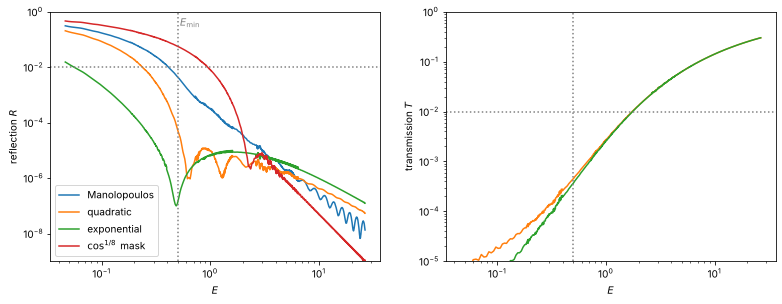

In [5]:
def plot_rt(axs, E, R, T, **kwargs):
    axs[0].loglog(E, R, **kwargs)
    axs[1].loglog(E, np.maximum(T, 1e-30), **kwargs)  # T = 0 for the divergent absorbers


def setup_rt(axs):
    for ax, label, ylim in zip(axs, ["reflection $R$", "transmission $T$"], [(1e-9, 1), (1e-5, 1)]):
        ax.axvline(E_min, color="gray", ls=":")
        ax.axhline(0.01, color="gray", ls=":")
        ax.set(xlabel="$E$", ylabel=label, ylim=ylim)
    axs[0].text(E_min * 1.05, 0.3, r"$E_\mathrm{min}$", color="gray")
    axs[0].legend()


results = {name: reflection(make) for name, make in absorbers.items()}
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (E, R, T) in results.items():
    plot_rt(axs, E, R, T, label=name)
setup_rt(axs)

All absorbers reflect slow waves, whose wavelength is long compared with the layer. Beyond that they differ:

* The **Manolopoulos** absorber keeps its promise: $R < 1\%$ above $E_\mathrm{min}$ ($5\cdot10^{-3}$ at
  $E_\mathrm{min}$), falling steadily with energy, and nothing is transmitted, since nothing passes the
  divergence.
* The **mask** transmits nothing either, but reflects more than 1% up to $E \approx 1.3$.
* The **quadratic** and the **exponential** absorber reflect less at low energies, the exponential one at most
  about 1%. But fast waves cross both layers before they are absorbed: above $E \approx 1.7$
  more than 1% get through, at $E = 25$ a third, and come back into the grid from the other side.

(Transmissions below about $10^{-5}$ are not resolved: at low energies, the strongly reflected wave has a
small tail at $+k$.)

## Strength versus width

For a CAP of finite strength there is no good choice for all energies: a weak one transmits fast waves,
a strong one reflects slow waves.

R(E_min) = 4.6e-03 for delta = 0.2, 3.6e-05 for delta = 0.1


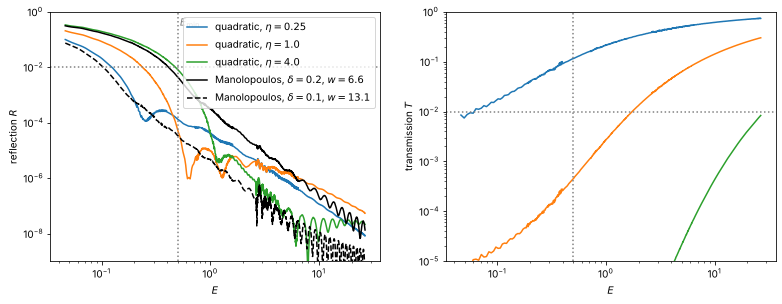

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for eta in [0.25, 1.0, 4.0]:
    plot_rt(axs, *reflection(lambda s, eta=eta: so.PowerAbsorber1d(w, eta, *s)), label=rf"quadratic, $\eta = {eta}$")
plot_rt(axs, *results["Manolopoulos"], color="k", label=rf"Manolopoulos, $\delta = 0.2$, $w = {w:.1f}$")
E, R, T = reflection(lambda s: so.ManolopoulosAbsorber1d(E_min, *s, delta=0.1))
plot_rt(axs, E, R, T, color="k", ls="--", label=rf"Manolopoulos, $\delta = 0.1$, $w = {2 * w:.1f}$")
setup_rt(axs)
i = np.argmin(np.abs(E - E_min))
print(f"R(E_min) = {results['Manolopoulos'][1][i]:.1e} for delta = 0.2, {R[i]:.1e} for delta = 0.1")

A stronger quadratic absorber transmits less ($\eta = 4$: below 1% up to $E \approx 9$) but reflects more
of the slow waves (above 1% up to $E \approx 0.6$). The Manolopoulos absorber has a single knob, $\delta$:
halving it doubles the width and lowers the reflection at $E_\mathrm{min}$ from $5\cdot10^{-3}$ to
$4\cdot10^{-5}$.

In practice: choose $E_\mathrm{min}$ somewhat below the lowest energy that has to leave the grid, e.g. the
lowest kinetic energy of the photoelectrons in an ionization problem, and use `ManolopoulosAbsorber1d`.
A tuned polynomial CAP can do better in a known energy window, if the layer is wide enough to stop the
fastest waves. Masks are simple, but their effect depends on the time step.

Things to try:

* `MaskAbsorber1d` with the time step halved but the mask unchanged: it then acts twice as often.
* A packet with a negative real part in the absorber, `ExpAbsorber1d(A_real < 0, ...)`, which speeds the wave
  up and shortens its wavelength (Hussain and Roberts, Phys. Rev. A **63**, 012703 (2000)).
* The same measurement for the absorber in the tunneling notebook (02), to check that it does not
  disturb the transmission probabilities computed there.